# Gauss-Bonnet with geomstats

Take the unit sphere. Its Gaussian curvature is $1$ at every point and its area is $4\pi$, so the integral of the curvature over the sphere is $4\pi$. Now project the edges of a cube onto the sphere from its center: the sphere splits into $6$ faces with $12$ edges and $8$ vertices, and $8 - 12 + 6 = 2$.

The Gauss-Bonnet theorem says that these two numbers are linked on every closed surface: the integral of the Gaussian curvature equals $2\pi$ times the number of vertices minus edges plus faces. For the sphere this is $4\pi = 2\pi \cdot 2$. The count, called the Euler characteristic, does not depend on how we cut the surface into polygons.

On other surfaces the integral of the curvature is harder to compute. The curvature changes from point to point, and computing it from the metric alone, that is, from lengths measured on the surface, needs derivatives of a parametrization up to the third order. By hand this is long and error-prone, and a numerical integral needs care where the parametrization degenerates, such as at the poles of a sphere.

We rely on the following references:

- **Theory:** [do Carmo](https://store.doverpublications.com/products/9780486806990) for the differential geometry of surfaces and the [Gauss-Bonnet theorem](https://en.wikipedia.org/wiki/Gauss%E2%80%93Bonnet_theorem).
- **Software:** [geomstats](https://github.com/geomstats/geomstats) ([Miolane et al.](https://jmlr.org/papers/v21/19-027.html)), which computes the curvature of a parametrized surface with automatic differentiation.
- **Quadrature:** [Trefethen and Weideman](https://doi.org/10.1137/130932132) on the trapezoidal rule for periodic integrands.

In this notebook we compute both sides of the theorem numerically for a sphere, a torus, and an ellipsoid, and check that they agree. We describe each surface by a parametrization, and geomstats derives the metric and the curvature from it with the automatic differentiation of PyTorch. For the right side we take a grid on the parameter rectangle, glue its edges the way the surface closes up, and count its vertices, edges, and faces.

We keep the setting simple on purpose:

- **Closed surfaces:** Our surfaces have no boundary, so the boundary term of the general theorem does not appear.
- **One chart per surface:** We parametrize each surface over one rectangle whose edges are either glued or collapsed to points.
- **Surfaces in $\mathbb{R}^3$:** The metric of each surface is the one induced by the Euclidean space around it.

We assume you know the basic objects of the differential geometry of surfaces (first fundamental form, Gaussian curvature) at the level of do Carmo, and that you have used automatic differentiation in PyTorch.

We use geomstats from the `main` branch (commit `1b42ec9`), for the reason we give in *Surfaces in geomstats*.

Here are the steps we follow:

1. **Prepare Notebook.** We select the PyTorch backend and import the libraries.
2. **The Gauss-Bonnet Theorem.** We state the theorem and look at two examples.
3. **Curvature in Coordinates.** We define the metric, the Christoffel symbols, the Riemann tensor, and two ways to compute the Gaussian curvature.
4. **Surfaces in geomstats.** We write each surface as a subclass of `ImmersedSet` and see which geomstats method computes each object.
5. **Curvature Checks.** We compare the curvature from geomstats with closed forms at random points.
6. **Curvature Maps.** We plot the curvature on each surface.
7. **Total Curvature.** We integrate the curvature with a quadrature rule that follows how the parameter rectangle closes up.
8. **Euler Characteristic.** We count the vertices, edges, and faces of a glued grid.
9. **Gauss-Bonnet Check.** We compare both sides for an increasing number of quadrature nodes.
10. **Conclusion.** We summarize the findings and the limitations, and give some recommendations.
11. **Next Steps.** We list what to try next.

## Prepare Notebook

We select the backend of geomstats with the `GEOMSTATS_BACKEND` environment variable before the first import, because geomstats reads it only then.

In [1]:
%env GEOMSTATS_BACKEND=pytorch

env: GEOMSTATS_BACKEND=pytorch


In [2]:
from enum import StrEnum
from typing import NamedTuple

import arviz as az
import geomstats.backend as gs
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from geomstats.geometry.base import ImmersedSet
from geomstats.geometry.euclidean import Euclidean
from matplotlib.colors import CenteredNorm
from numpy.typing import NDArray
from torch import Tensor

seed: int = 42
rng: np.random.Generator = np.random.default_rng(seed=seed)

HDI_PROB = 0.94

az.style.use("arviz-darkgrid")
az.rcParams["stats.ci_kind"] = "hdi"
az.rcParams["stats.ci_prob"] = HDI_PROB
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

%config InlineBackend.figure_format = "retina"

We check with an `assert` that geomstats uses the PyTorch backend in double precision. We need double precision because the checks below compare curvatures at round-off level, about $10^{-14}$, far below the round-off of single precision.

In [3]:
assert gs.__name__ == "geomstats.pytorch"
assert gs.array(0.0).dtype == gs.float64

Now that geomstats runs in double precision, we can state the theorem.

## The Gauss-Bonnet Theorem

Let $M$ be a compact, oriented, two-dimensional Riemannian manifold with a smooth (possibly empty) boundary $\partial M$. We use the following notation:

- $K$ is the **Gaussian curvature** of $M$ and $dA$ is its **area element**.
- $k_g$ is the **geodesic curvature** of the boundary and $ds$ is the arc length along it.
- $\chi(M) = V - E + F$ is the **Euler characteristic** of $M$, where $V$, $E$, and $F$ are the numbers of vertices, edges, and faces of any polygonal decomposition of $M$ (see [Euler characteristic](https://en.wikipedia.org/wiki/Euler_characteristic)).

With this notation, the [Gauss-Bonnet theorem](https://en.wikipedia.org/wiki/Gauss%E2%80%93Bonnet_theorem) states that

$$
\int_M K \, dA + \int_{\partial M} k_g \, ds = 2 \pi \chi(M).
$$

When $M$ is closed, that is, compact and without boundary, the boundary term is absent:

$$
\int_M K \, dA = 2 \pi \chi(M).
$$

This is the case we treat here. The left side depends only on the metric of the surface, which measures lengths inside it. The right side depends only on its topology.

Here is an important observation: when we deform a surface smoothly, the values of $K$ and $dA$ at each point change, but the integral of $K \, dA$ stays the same.

For a closed orientable surface, the Euler characteristic is $\chi = 2 - 2 \, \text{genus}$, where the genus is the number of holes. A sphere of radius $\rho$ has genus $0$, constant curvature $K = 1 / \rho^2$, and area $4 \pi \rho^2$, so its total curvature, the integral of $K \, dA$, is $4 \pi = 2 \pi \cdot 2$ for every radius. A torus has genus $1$ and $\chi = 0$: its curvature is positive on the outer half and negative on the inner half, and the two parts cancel.

To compute the left side on other surfaces, we need $K$ in the coordinates of a parametrization.

## Curvature in Coordinates

We describe a surface by an **immersion** $f: U \to \mathbb{R}^3$ of a parameter domain $U \subset \mathbb{R}^2$, written $(u, v) \mapsto f(u, v)$. We write $\partial_i$ for the partial derivative with respect to the coordinate $i \in \{u, v\}$, and we sum over repeated indices. Every object below is a function on $U$ built from derivatives of $f$.

The **pullback metric**, also called the first fundamental form, is the matrix of inner products of the first derivatives of $f$,

$$
g_{ij} = \langle \partial_i f, \partial_j f \rangle,
$$

and the area element is $dA = \sqrt{\det g} \, du \, dv$. We write $g^{ij}$ for the entries of the inverse matrix $g^{-1}$.

The **Christoffel symbols** of the Levi-Civita connection $\nabla$ need the first derivatives of $g$, which are second derivatives of $f$:

$$
\Gamma^k_{ij} = \frac{1}{2} g^{kl} \left( \partial_i g_{jl} + \partial_j g_{il} - \partial_l g_{ij} \right).
$$

The **Riemann curvature tensor** needs the first derivatives of $\Gamma$, which are third derivatives of $f$. In the index convention of geomstats it reads

$$
R^l_{ijk} = \partial_j \Gamma^l_{ki} - \partial_k \Gamma^l_{ji} + \Gamma^l_{jm} \Gamma^m_{ki} - \Gamma^l_{km} \Gamma^m_{ji}.
$$

For vector fields $X$, $Y$, $Z$ on $U$ with Lie bracket $[X, Y]$, these are the components of the curvature map $R(X, Y) Z = \nabla_X \nabla_Y Z - \nabla_Y \nabla_X Z - \nabla_{[X, Y]} Z$ in coordinates, $R(\partial_j, \partial_k) \partial_i = R^l_{ijk} \partial_l$. Textbooks differ in the sign and the index order of $R$, so we use the convention of geomstats throughout.

A surface has a single tangent plane at each point, and its Gaussian curvature is the **sectional curvature** of that plane. In coordinates,

$$
K = \frac{\langle R(\partial_u, \partial_v) \partial_v, \partial_u \rangle}{g_{uu} g_{vv} - g_{uv}^2} = \frac{g_{ul} R^l_{vuv}}{\det g},
$$

where the inner product is the one given by $g$. This is the **intrinsic** route to $K$, because it only uses $g$ and its derivatives.

There is also an **extrinsic** route. It uses the unit normal $N$ and the **second fundamental form** $h$,

$$
N = \frac{\partial_u f \times \partial_v f}{\| \partial_u f \times \partial_v f \|}, \qquad h_{ij} = \langle \partial_i \partial_j f, N \rangle, \qquad K = \frac{\det h}{\det g}.
$$

Here are two important remarks. First, the extrinsic route needs second derivatives of $f$, while the intrinsic route needs third derivatives. Second, Gauss's [Theorema Egregium](https://en.wikipedia.org/wiki/Theorema_Egregium) says that both routes give the same $K$.

In particular, $K$ does not change when we bend a surface without stretching it, because bending does not change $g$. We compare both routes in *Curvature Checks*, after we see how geomstats computes each of these objects.

## Surfaces in geomstats

In geomstats, a parametrized manifold is an `ImmersedSet`. Its points are intrinsic coordinates $(u, v)$, and a subclass implements the method `immersion`, which is our $f$. The default metric of an `ImmersedSet` is a `PullbackMetric`, whose methods compute the objects of *Curvature in Coordinates*.

### Derivative Chain

The metric computes these objects in four steps:

1. **Metric.** `jacobian_immersion` differentiates `immersion` once, and `metric.metric_matrix` builds $g$ from the Jacobian.
2. **Christoffel symbols.** `hessian_immersion` differentiates `immersion` twice, `metric.inner_product_derivative_matrix` builds $\partial_k g_{ij}$ from the Jacobian and the Hessian, and `metric.christoffels` builds $\Gamma$.
3. **Riemann tensor.** `metric.riemann_tensor` differentiates `metric.christoffels` once more and assembles $R$.
4. **Sectional curvature.** `metric.sectional_curvature` contracts $R$ with two tangent vectors and divides by $g_{uu} g_{vv} - g_{uv}^2$.

Three conventions matter when we read these arrays:

- **Christoffel symbols:** The contravariant index comes first, so `christoffels[..., k, i, j]` is $\Gamma^k_{ij}$.
- **Riemann tensor:** The contravariant index comes last, so `riemann_tensor[..., i, j, k, l]` is $R^l_{ijk}$.
- **Hessian:** The indices of differentiation come last, so `hessian_immersion[..., :, i, j]` is the vector $\partial_i \partial_j f$.

In the PyTorch backend, `gs.autodiff.jacobian_vec` and `gs.autodiff.hessian_vec` loop over the points and call `torch.autograd.functional.jacobian` and `torch.autograd.functional.hessian` with `create_graph=point.requires_grad` (see [`autodiff.py`](https://github.com/geomstats/geomstats/blob/1b42ec9fa9879cdfedf79cadc5adaeca300bf51b/geomstats/_backend/pytorch/autodiff.py)). PyTorch sets `requires_grad` on the inputs it differentiates, so the Jacobian and the Hessian of step $2$ keep their computational graph exactly when the outer derivative of step $3$ needs it. The loops over points also set the cost, which grows linearly with the number of points at which we evaluate $K$.

Before [#2142](https://github.com/geomstats/geomstats/pull/2142), the PyTorch backend dropped the graph of the inner derivatives, so the derivative of $\Gamma$ in step $3$ was zero and the intrinsic $K$ was wrong without a warning. This affects the `2.8.0` release: the pull request reports $2.14$ and $-0.66$ at two test points instead of $1$ for the unit sphere.

### Base Class

To integrate and to count, we also need to know how the parameter rectangle $U = [u_{\min}, u_{\max}] \times [v_{\min}, v_{\max}]$ closes up into the surface. A **closure** describes one parameter direction:

- **Periodic:** The two opposite edges are glued, as for an angle.
- **Pole:** Each of the two edges collapses to a single point, as for the polar angle of a sphere.

The quadrature rule of the left side and the glued grid of the right side both depend on the closures. The base class `ClosedSurface` stores them with the parameter ranges, and adds the area element and the two routes to $K$:

In [4]:
class Closure(StrEnum):
    """How one parameter direction of the rectangle closes up."""

    PERIODIC = "periodic"
    POLE = "pole"


class ClosedSurface(ImmersedSet):
    """Closed surface in R^3 parametrized over a rectangle.

    Subclasses implement `immersion` and set the class attributes below.
    The methods take points of shape [n_points, 2].

    Attributes
    ----------
    domain : tuple[tuple[float, float], tuple[float, float]]
        Parameter ranges ((u_min, u_max), (v_min, v_max)).
    closures : tuple[Closure, Closure]
        How each parameter direction closes up.
    """

    domain: tuple[tuple[float, float], tuple[float, float]]
    closures: tuple[Closure, Closure]

    def __init__(self) -> None:
        super().__init__(dim=2)

    def _define_embedding_space(self) -> Euclidean:
        return Euclidean(dim=3)

    def area_element(self, points: Tensor) -> Tensor:
        """Area element sqrt(det g)."""
        return gs.sqrt(gs.linalg.det(self.metric.metric_matrix(points)))

    def gaussian_curvature(self, points: Tensor) -> Tensor:
        """Intrinsic K, the sectional curvature of the coordinate plane."""
        d_u, d_v = gs.eye(2)
        return self.metric.sectional_curvature(d_u, d_v, points)

    def gaussian_curvature_extrinsic(self, points: Tensor) -> Tensor:
        """Extrinsic K = det(h) / det(g) with h_ij = <d_i d_j f, N>."""
        d_u_f, d_v_f = gs.moveaxis(self.jacobian_immersion(points), -1, 0)
        normal = gs.cross(d_u_f, d_v_f)
        normal = normal / gs.linalg.norm(normal, axis=-1, keepdims=True)
        h = gs.einsum("...aij,...a->...ij", self.hessian_immersion(points), normal)
        return gs.linalg.det(h) / gs.linalg.det(self.metric.metric_matrix(points))

### Ellipsoid and Torus

Each surface is a subclass that sets `domain` and `closures` and implements `immersion`. The ellipsoid with semi-axes $a$, $b$, $c$ uses as its coordinates $(u, v)$ the polar angle $\theta \in [0, \pi]$, which ends at two poles, and the periodic azimuth $\varphi \in [0, 2\pi]$:

$$
f(\theta, \varphi) = \left( a \sin\theta \cos\varphi, \; b \sin\theta \sin\varphi, \; c \cos\theta \right).
$$

The torus with major radius $D$ (the distance from the center of the tube to the axis) and minor radius $r$ uses the angle $u$ around the tube and the angle $v$ around the hole, and both are periodic:

$$
f(u, v) = \left( (D + r \cos u) \cos v, \; (D + r \cos u) \sin v, \; r \sin u \right).
$$

Each subclass also has the closed form of $K$, which we use only as a check. For the ellipsoid, [MathWorld](https://mathworld.wolfram.com/Ellipsoid.html) gives the curvature at the point $(x, y, z)$,

$$
K = \frac{1}{a^2 b^2 c^2 \left( x^2 / a^4 + y^2 / b^4 + z^2 / c^4 \right)^2},
$$

and the sphere of radius $\rho$ is the case $a = b = c = \rho$ with $K = 1 / \rho^2$. For the torus, $K = \cos u / \left( r (D + r \cos u) \right)$.

In [5]:
class Ellipsoid(ClosedSurface):
    """Ellipsoid with polar angle theta in [0, pi] and azimuth phi in [0, 2 pi].

    Parameters
    ----------
    a, b, c : float
        Semi-axes along x, y, and z.
    """

    domain = ((0.0, np.pi), (0.0, 2 * np.pi))
    closures = (Closure.POLE, Closure.PERIODIC)

    def __init__(self, a: float, b: float, c: float) -> None:
        self.a, self.b, self.c = a, b, c
        super().__init__()

    def immersion(self, point: Tensor) -> Tensor:
        theta, phi = gs.moveaxis(point, -1, 0)
        return gs.stack(
            [
                self.a * gs.sin(theta) * gs.cos(phi),
                self.b * gs.sin(theta) * gs.sin(phi),
                self.c * gs.cos(theta),
            ],
            axis=-1,
        )

    def gaussian_curvature_closed_form(self, points: Tensor) -> Tensor:
        """Closed-form K, used as a check."""
        x, y, z = gs.moveaxis(self.immersion(points), -1, 0)
        a, b, c = self.a, self.b, self.c
        return 1 / (a * b * c * (x**2 / a**4 + y**2 / b**4 + z**2 / c**4)) ** 2


class Torus(ClosedSurface):
    """Ring torus with angle u around the tube and angle v around the hole.

    Parameters
    ----------
    major_radius : float
        Distance D from the center of the tube to the axis of the torus.
    minor_radius : float
        Radius r of the tube.
    """

    domain = ((0.0, 2 * np.pi), (0.0, 2 * np.pi))
    closures = (Closure.PERIODIC, Closure.PERIODIC)

    def __init__(self, major_radius: float, minor_radius: float) -> None:
        self.major_radius, self.minor_radius = major_radius, minor_radius
        super().__init__()

    def immersion(self, point: Tensor) -> Tensor:
        u, v = gs.moveaxis(point, -1, 0)
        distance_to_axis = self.major_radius + self.minor_radius * gs.cos(u)
        return gs.stack(
            [
                distance_to_axis * gs.cos(v),
                distance_to_axis * gs.sin(v),
                self.minor_radius * gs.sin(u),
            ],
            axis=-1,
        )

    def gaussian_curvature_closed_form(self, points: Tensor) -> Tensor:
        """Closed-form K, used as a check."""
        u, _ = gs.moveaxis(points, -1, 0)
        distance_to_axis = self.major_radius + self.minor_radius * gs.cos(u)
        return gs.cos(u) / (self.minor_radius * distance_to_axis)


surfaces: dict[str, Ellipsoid | Torus] = {
    "sphere": Ellipsoid(a=1.0, b=1.0, c=1.0),
    "torus": Torus(major_radius=2.0, minor_radius=0.7),
    "ellipsoid": Ellipsoid(a=1.0, b=1.5, c=0.6),
}

Next, let's check the curvature of the three surfaces.

## Curvature Checks

Before we integrate anything, we check $K$ pointwise, because an error in an index convention or in a nested derivative would show up here. For each surface we draw $20$ random points in the parameter rectangle and compute $K$ in three ways: the intrinsic route, the closed form, and the extrinsic route.

In [6]:
def curvature_samples(
    surface: Ellipsoid | Torus, rng: np.random.Generator, n_points: int = 20
) -> pl.DataFrame:
    """Intrinsic, closed-form, and extrinsic K at random points.

    Parameters
    ----------
    surface : Ellipsoid | Torus
        Surface to check.
    rng : np.random.Generator
        Random number generator for the points.
    n_points : int
        Number of random points.

    Returns
    -------
    pl.DataFrame
        One row per point with the columns `intrinsic`, `closed_form`, and `extrinsic`.
    """
    low, high = np.array(surface.domain).T
    points = gs.array(rng.uniform(low, high, size=(n_points, 2)))
    return pl.DataFrame(
        {
            "intrinsic": gs.to_numpy(surface.gaussian_curvature(points)),
            "closed_form": gs.to_numpy(surface.gaussian_curvature_closed_form(points)),
            "extrinsic": gs.to_numpy(surface.gaussian_curvature_extrinsic(points)),
        }
    )


checks = pl.concat(
    [
        curvature_samples(surface, rng).with_columns(surface=pl.lit(name))
        for name, surface in surfaces.items()
    ]
)

REFERENCES = {"closed_form": "closed form", "extrinsic": "extrinsic route"}
CURVATURE_TOLERANCE = 1e-12

max_abs_diff = checks.group_by("surface", maintain_order=True).agg(
    (pl.col("intrinsic") - pl.col(reference)).abs().max().alias(reference)
    for reference in REFERENCES
)

assert all(
    max_abs_diff[reference].max() < CURVATURE_TOLERANCE for reference in REFERENCES
)

We plot the largest absolute difference between the intrinsic $K$ and each reference on a log axis:

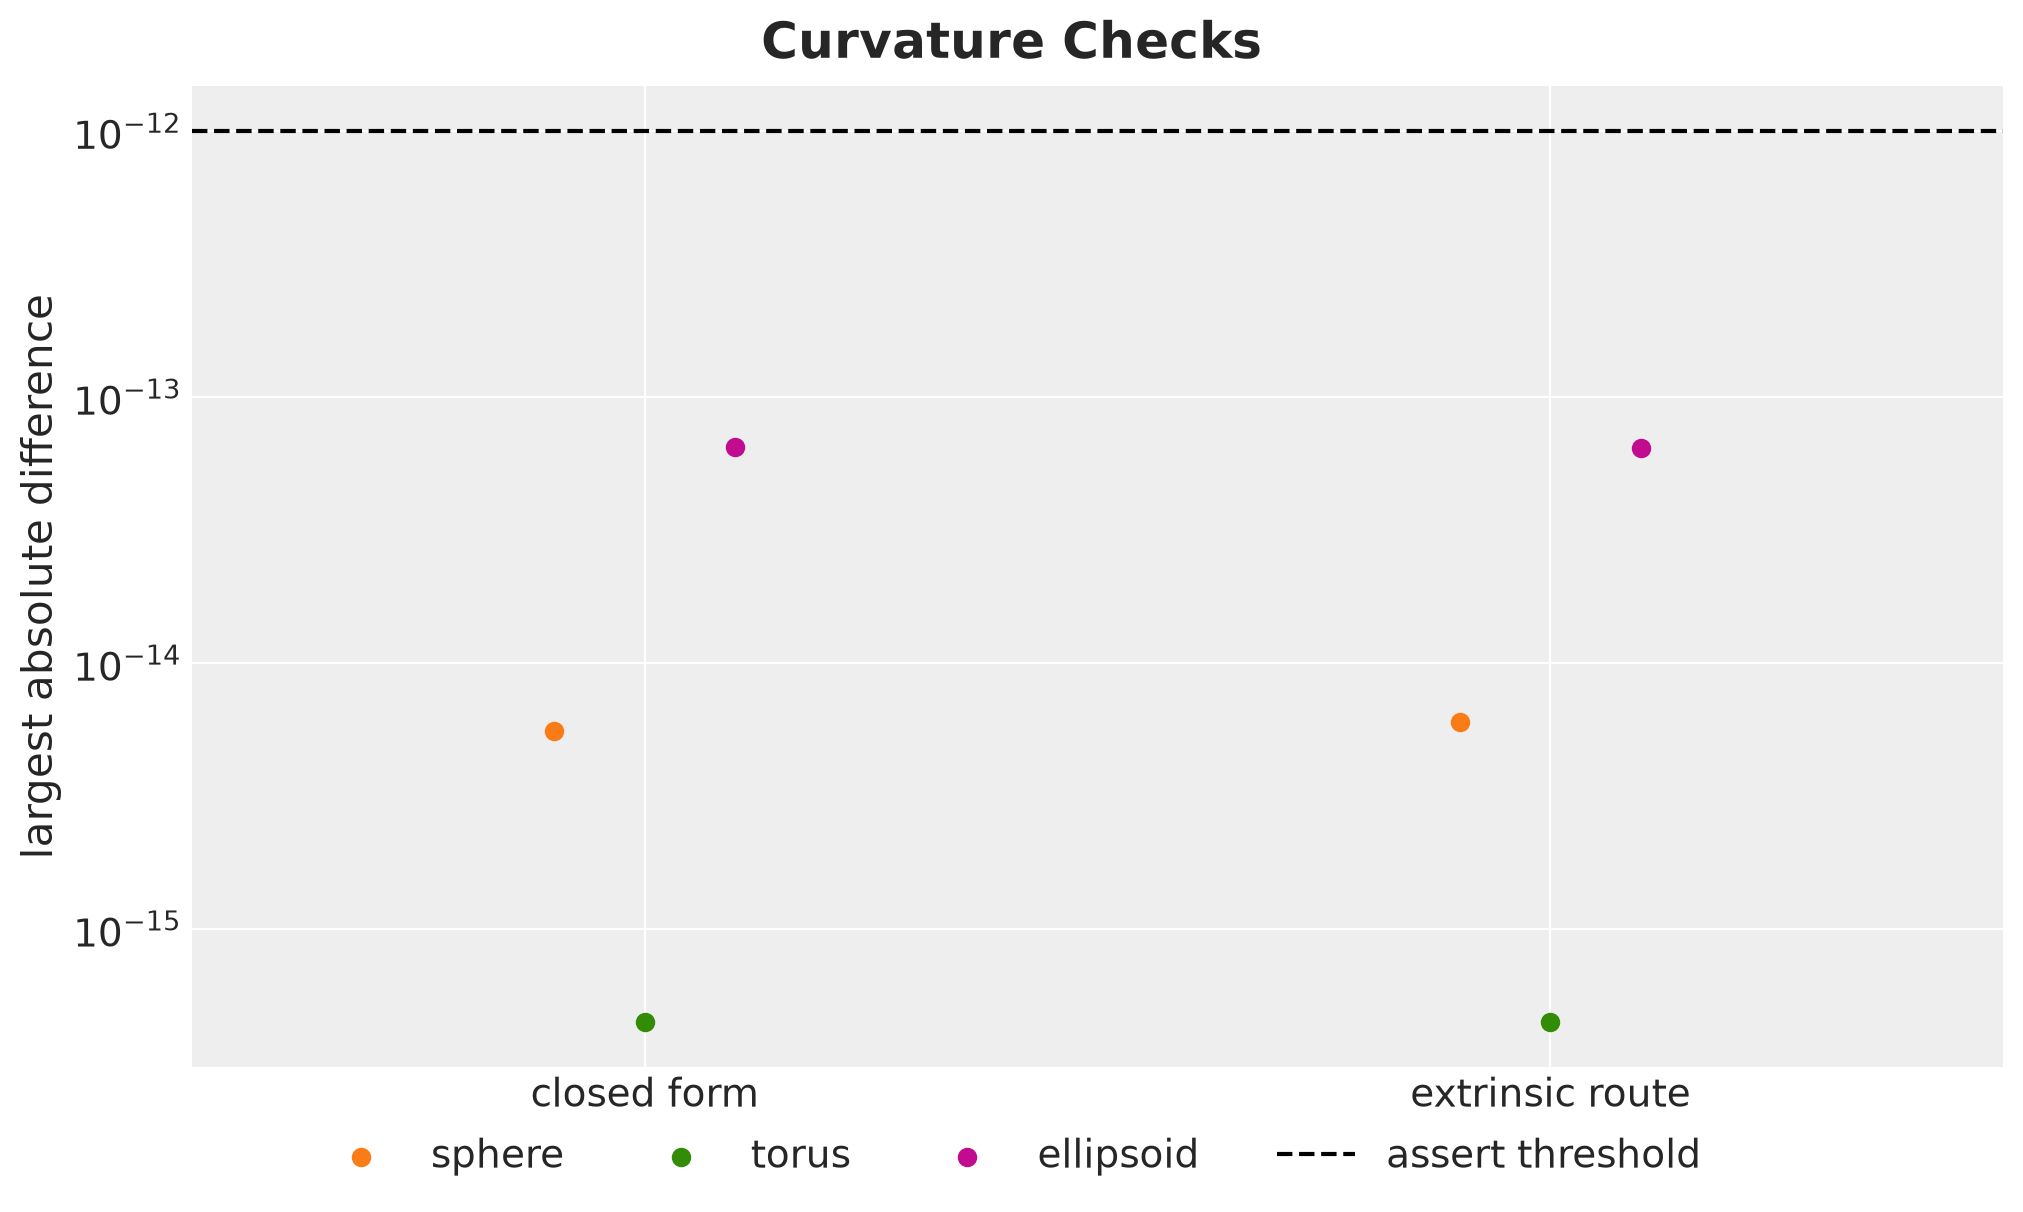

In [7]:
SURFACE_COLORS = {"sphere": "C1", "torus": "C2", "ellipsoid": "C3"}

fig, ax = plt.subplots(layout="constrained")
positions = np.arange(len(REFERENCES))

for offset, (name, color) in zip((-0.1, 0.0, 0.1), SURFACE_COLORS.items(), strict=True):
    row = max_abs_diff.filter(pl.col("surface") == name).select(list(REFERENCES))
    ax.scatter(positions + offset, row.row(0), color=color, label=name)

ax.axhline(CURVATURE_TOLERANCE, color="black", linestyle="--", label="assert threshold")
ax.set(
    yscale="log",
    xticks=positions,
    xticklabels=list(REFERENCES.values()),
    xlim=(-0.5, len(REFERENCES) - 0.5),
    ylabel="largest absolute difference",
)
fig.legend(loc="outside lower center", ncol=4)
fig.suptitle("Curvature Checks", fontsize=18, fontweight="bold");

All differences are at round-off level and below the threshold. The closed form checks the whole intrinsic route, including the nested derivative of step $3$, and the extrinsic route checks the Theorema Egregium at these points: the second and the third derivatives of $f$ give the same curvature.

Now that we trust $K$, let's look at how it varies over each surface.

## Curvature Maps

We evaluate the intrinsic $K$ at the centers of a uniform $24 \times 24$ grid on the parameter rectangle of each surface. This takes a while, because each point needs its own Riemann tensor.

In [8]:
%%time


class CurvatureMap(NamedTuple):
    """Surface points on a grid of the parameter rectangle and K at the cell centers."""

    surface_points: NDArray  # shape [n_cells + 1, n_cells + 1, 3]
    curvature: NDArray  # shape [n_cells, n_cells]


def curvature_map(surface: ClosedSurface, n_cells: int = 24) -> CurvatureMap:
    """Evaluate the surface on a uniform grid and K at the cell centers.

    Parameters
    ----------
    surface : ClosedSurface
        Surface to evaluate.
    n_cells : int
        Number of grid cells per parameter direction.

    Returns
    -------
    CurvatureMap
        Points on the grid vertices and K at the cell centers.
    """
    (u_min, u_max), (v_min, v_max) = surface.domain
    u, v = np.meshgrid(
        np.linspace(u_min, u_max, n_cells + 1),
        np.linspace(v_min, v_max, n_cells + 1),
        indexing="ij",
    )
    vertices = np.stack([u, v], axis=-1)
    centers = (vertices[:-1, :-1] + vertices[1:, 1:]) / 2
    # The metric methods of geomstats expect a flat batch of points.
    curvature = surface.gaussian_curvature(gs.array(centers.reshape(-1, 2)))
    return CurvatureMap(
        surface_points=gs.to_numpy(surface.immersion(gs.array(vertices))),
        curvature=gs.to_numpy(curvature).reshape(n_cells, n_cells),
    )


curvature_maps = {name: curvature_map(surface) for name, surface in surfaces.items()}

CPU times: user 23.4 s, sys: 91.7 ms, total: 23.5 s
Wall time: 23.5 s


We color each cell of a surface by its value of $K$. The colormap is centered at $K = 0$, so red cells have positive and blue cells negative curvature.

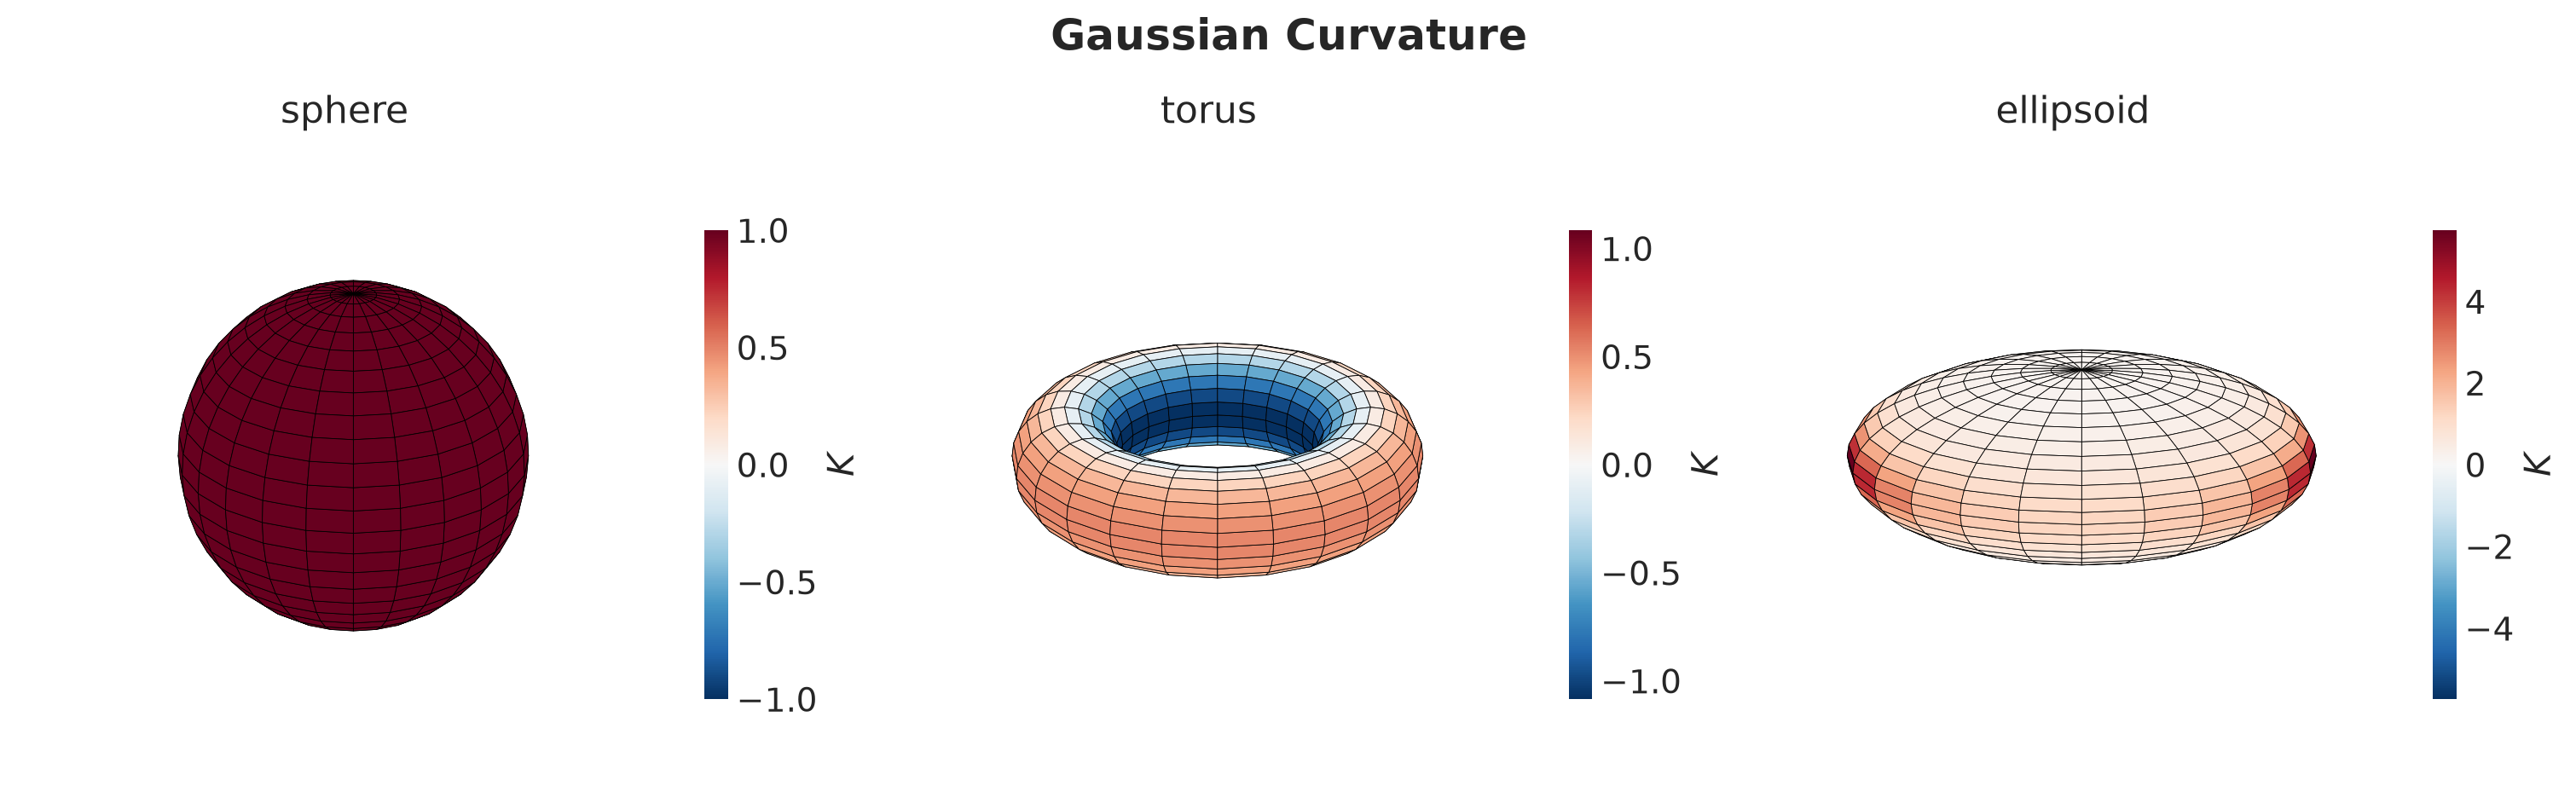

In [9]:
cmap = plt.colormaps["RdBu_r"]

fig, axes = plt.subplots(
    1, 3, figsize=(15, 5), subplot_kw={"projection": "3d"}, layout="constrained"
)

for ax, (name, curvature_map_) in zip(axes, curvature_maps.items(), strict=True):
    norm = CenteredNorm()
    ax.plot_surface(
        *np.moveaxis(curvature_map_.surface_points, -1, 0),
        facecolors=cmap(norm(curvature_map_.curvature)),
        edgecolor="black",
        linewidth=0.3,
        shade=False,
    )
    ax.set_aspect("equal")
    ax.view_init(elev=25, azim=0)
    ax.set_axis_off()
    ax.set_facecolor("white")
    ax.set_title(name)
    fig.colorbar(
        plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.6, label="$K$"
    )

fig.suptitle("Gaussian Curvature", fontsize=18, fontweight="bold");

The colors show where each surface curves:

- **Sphere.** It has a single color because its curvature is constant.
- **Torus.** It is red on the outer half and blue on the inner half, the two parts that cancel in its total curvature. From the closed form, the inner half is more curved, down to $-1 / \left( r (D - r) \right) \approx -1.10$ against up to $1 / \left( r (D + r) \right) \approx 0.53$, but it has less area.
- **Ellipsoid.** It is red near the two ends of its longest axis and almost white elsewhere, so its curvature is concentrated near these ends. The closed form gives $K = b^2 / (a^2 c^2) = 6.25$ there, and the colorbar stops below that value because the cell centers miss the ends.

Next, let's integrate $K$ over each surface.

## Total Curvature

We now turn to the left side of the theorem. Over the parameter rectangle, the total curvature is

$$
\int_M K \, dA = \int_{u_{\min}}^{u_{\max}} \int_{v_{\min}}^{v_{\max}} K(u, v) \sqrt{\det g(u, v)} \, dv \, du.
$$

We take nodes $u_p$ with weights $\alpha_p$ in the first direction and nodes $v_q$ with weights $\beta_q$ in the second direction, for $p, q = 1, \ldots, n$, and approximate the integral by the tensor-product sum

$$
\int_M K \, dA \approx \sum_{p=1}^{n} \sum_{q=1}^{n} \alpha_p \beta_q \, K(u_p, v_q) \sqrt{\det g(u_p, v_q)}.
$$

The one-dimensional rule follows the closure. In a periodic direction we use the composite midpoint rule, which for a periodic integrand is the trapezoidal rule on a grid shifted by half a step. [Trefethen and Weideman](https://doi.org/10.1137/130932132) open their review of this rule with the following sentence:

> It is well known that the trapezoidal rule converges geometrically when applied to analytic functions on periodic intervals or the real line.

In a direction that ends at poles, let $\psi(\theta)$ be the integrand as a function of the polar angle $\theta \in [0, \pi]$ at a fixed azimuth. It is smooth but not periodic. With step $\delta = \pi / n$, the [Euler-Maclaurin formula](https://en.wikipedia.org/wiki/Euler%E2%80%93Maclaurin_formula) gives the leading error term of the midpoint rule:

$$
\frac{\delta^2}{24} \left( \psi'(\pi) - \psi'(0) \right).
$$

On our ellipsoids $K > 0$ and $\sqrt{\det g}$ vanishes like $\sin\theta$ at each pole, so $\psi'(0) > 0 > \psi'(\pi)$. The term does not vanish, and the error decays only as $n^{-2}$.

There we use Gauss-Legendre nodes instead, which converge geometrically in $n$ for an integrand that is analytic around the interval (Theorem $4.5$ in [Trefethen](https://doi.org/10.1137/060659831)). Both rules only use interior nodes. This matters because $\det g = 0$ at a pole, so the inverse metric $g^{-1}$ in the Christoffel symbols does not exist there.

For the torus, $\sqrt{\det g} = r (D + r \cos u)$, so the integrand is $K \sqrt{\det g} = \cos u$. The midpoint rule integrates $\cos u$ over a full period exactly for $n \geq 2$, so we expect the torus to be exact at every resolution.

The code follows the formula: we build the two one-dimensional rules, take their tensor product, and sum $K \sqrt{\det g}$ times the weights. As a first test of the claim above, we integrate over the torus with only $n = 2$ nodes per direction.

In [10]:
class QuadratureRule(NamedTuple):
    """Nodes and weights of a one-dimensional quadrature rule."""

    nodes: NDArray
    weights: NDArray


def quadrature_rule(
    lower: float, upper: float, closure: Closure, n_nodes: int
) -> QuadratureRule:
    """One-dimensional quadrature rule on [lower, upper] that follows the closure.

    Parameters
    ----------
    lower, upper : float
        Ends of the interval.
    closure : Closure
        Midpoint rule for a periodic direction, Gauss-Legendre for a pole direction.
    n_nodes : int
        Number of nodes.

    Returns
    -------
    QuadratureRule
        Nodes and weights, both of shape [n_nodes].
    """

    if closure == Closure.PERIODIC:
        step = (upper - lower) / n_nodes
        return QuadratureRule(
            nodes=lower + step * (np.arange(n_nodes) + 0.5),
            weights=np.full(n_nodes, step),
        )

    nodes, weights = np.polynomial.legendre.leggauss(n_nodes)
    half_width = (upper - lower) / 2
    return QuadratureRule(
        nodes=lower + half_width * (nodes + 1), weights=half_width * weights
    )


def total_curvature(surface: ClosedSurface, n_nodes: int) -> float:
    """Tensor-product quadrature of K sqrt(det g) over the parameter rectangle.

    Parameters
    ----------
    surface : ClosedSurface
        Surface to integrate over.
    n_nodes : int
        Number of nodes per parameter direction.

    Returns
    -------
    float
        Approximation of the integral of K dA.
    """
    (u_range, v_range), (u_closure, v_closure) = surface.domain, surface.closures
    u_rule = quadrature_rule(*u_range, u_closure, n_nodes)
    v_rule = quadrature_rule(*v_range, v_closure, n_nodes)
    u_grid, v_grid = np.meshgrid(u_rule.nodes, v_rule.nodes, indexing="ij")
    points = gs.array(np.stack([u_grid.ravel(), v_grid.ravel()], axis=-1))
    weights = gs.array(np.outer(u_rule.weights, v_rule.weights).ravel())
    integrand = surface.gaussian_curvature(points) * surface.area_element(points)
    return float(gs.sum(weights * integrand))


total_curvature(surfaces["torus"], n_nodes=2)

-3.068089374008731e-15

The result is $-3.07 \times 10^{-15}$, zero up to round-off, as we expected.

With the left side in place, we turn to the right side.

## Euler Characteristic

For the right side we need $\chi = V - E + F$. We build a polygonal decomposition from a grid of $n_{\text{cells}} \times n_{\text{cells}}$ quads on the parameter rectangle and glue it according to the closures. Each grid vertex gets an integer label, and glued vertices share a label:

- **Periodic:** The last row of vertices in this direction takes the labels of the first row.
- **Pole:** Every vertex of each boundary row takes the label of one vertex in that row.

Let's work a small example. Here are the labels of the sphere grid with $n_{\text{cells}} = 4$, where rows follow the polar angle $\theta$ and columns follow the azimuth $\varphi$:

In [11]:
def glued_labels(closures: tuple[Closure, Closure], n_cells: int) -> NDArray:
    """Integer labels of the vertices of an n_cells x n_cells grid after gluing.

    Parameters
    ----------
    closures : tuple[Closure, Closure]
        How each parameter direction closes up.
    n_cells : int
        Number of grid cells per direction.

    Returns
    -------
    NDArray
        Labels of shape [n_cells + 1, n_cells + 1]. Glued vertices share a label.
    """
    labels = np.arange((n_cells + 1) ** 2).reshape(n_cells + 1, n_cells + 1)

    for axis, closure in enumerate(closures):
        # A view, so writing to `rows` writes to `labels`.
        rows = np.moveaxis(labels, axis, 0)

        if closure == Closure.PERIODIC:
            rows[-1] = rows[0]
        else:
            rows[0] = rows[0, 0]
            rows[-1] = rows[-1, 0]

    return labels


glued_labels(surfaces["sphere"].closures, n_cells=4)

array([[ 0,  0,  0,  0,  0],
       [ 5,  6,  7,  8,  5],
       [10, 11, 12, 13, 10],
       [15, 16, 17, 18, 15],
       [20, 20, 20, 20, 20]])

The labels are the vertex numbers of the grid before gluing. The first row carries the single label $0$ and the last row the single label $20$: these are the two poles. The last column repeats the first column, which glues the seam of the azimuth.

We then count distinct labels, distinct edges between two different labels, and faces. A quad that touches a pole has two corners with the same label, so it becomes a triangle. We identify an edge by its two end labels, which needs at least three cells per direction: with two cells, two different edges of a periodic direction join the same two vertices.

In [12]:
class CellCount(NamedTuple):
    """Numbers of vertices, edges, and faces of a glued grid."""

    vertices: int
    edges: int
    faces: int

    @property
    def euler_characteristic(self) -> int:
        return self.vertices - self.edges + self.faces


def count_cells(closures: tuple[Closure, Closure], n_cells: int) -> CellCount:
    """Count the vertices, edges, and faces of the glued grid.

    Parameters
    ----------
    closures : tuple[Closure, Closure]
        How each parameter direction closes up.
    n_cells : int
        Number of grid cells per direction, at least 3 so that no two edges
        join the same two vertices.

    Returns
    -------
    CellCount
        Numbers of vertices, edges, and faces.
    """
    labels = glued_labels(closures, n_cells)
    vertices = set(labels.ravel().tolist())
    edges = set()

    for starts, ends in [(labels[:-1], labels[1:]), (labels[:, :-1], labels[:, 1:])]:
        for start, end in zip(
            starts.ravel().tolist(), ends.ravel().tolist(), strict=True
        ):
            if start != end:  # an edge on a pole collapses to a point
                edges.add(frozenset((start, end)))

    corners = np.stack(
        [labels[:-1, :-1], labels[1:, :-1], labels[1:, 1:], labels[:-1, 1:]], axis=-1
    )
    faces = sum(len(set(quad)) >= 3 for quad in corners.reshape(-1, 4).tolist())
    return CellCount(vertices=len(vertices), edges=len(edges), faces=faces)


count_cells(surfaces["sphere"].closures, n_cells=4)

CellCount(vertices=14, edges=28, faces=16)

For the sphere grid we get $\chi = 14 - 28 + 16 = 2$. We now compute $\chi$ for each surface on a finer grid, and check with an `assert` that the value does not depend on the grid size:

In [13]:
chi = {
    name: count_cells(surface.closures, n_cells=12).euler_characteristic
    for name, surface in surfaces.items()
}

assert all(
    count_cells(surface.closures, n_cells).euler_characteristic == chi[name]
    for name, surface in surfaces.items()
    for n_cells in (4, 8, 16)
)

chi

{'sphere': 2, 'torus': 0, 'ellipsoid': 2}

The sphere and the ellipsoid have $\chi = 2$ and the torus has $\chi = 0$, which matches $\chi = 2 - 2 \, \text{genus}$ with genus $0$ and $1$.

Now that we have both sides, we can compare them.

## Gauss-Bonnet Check

Finally, we compare both sides for $n = 4, 8, 16, 32$ nodes per direction. This means $4080$ points in total ($3$ surfaces times $16 + 64 + 256 + 1024$ points), each with its own Riemann tensor.

In [14]:
%%time
N_NODES = (4, 8, 16, 32)

results = pl.DataFrame(
    [
        {
            "surface": name,
            "n_nodes": n_nodes,
            "abs_error": abs(total_curvature(surface, n_nodes) - 2 * np.pi * chi[name]),
        }
        for name, surface in surfaces.items()
        for n_nodes in N_NODES
    ]
)

assert results.filter(pl.col("n_nodes") == max(N_NODES))["abs_error"].max() < 1e-5

CPU times: user 59.2 s, sys: 342 ms, total: 59.6 s
Wall time: 1min


We plot the absolute difference between the two sides against $n$, on a log axis:

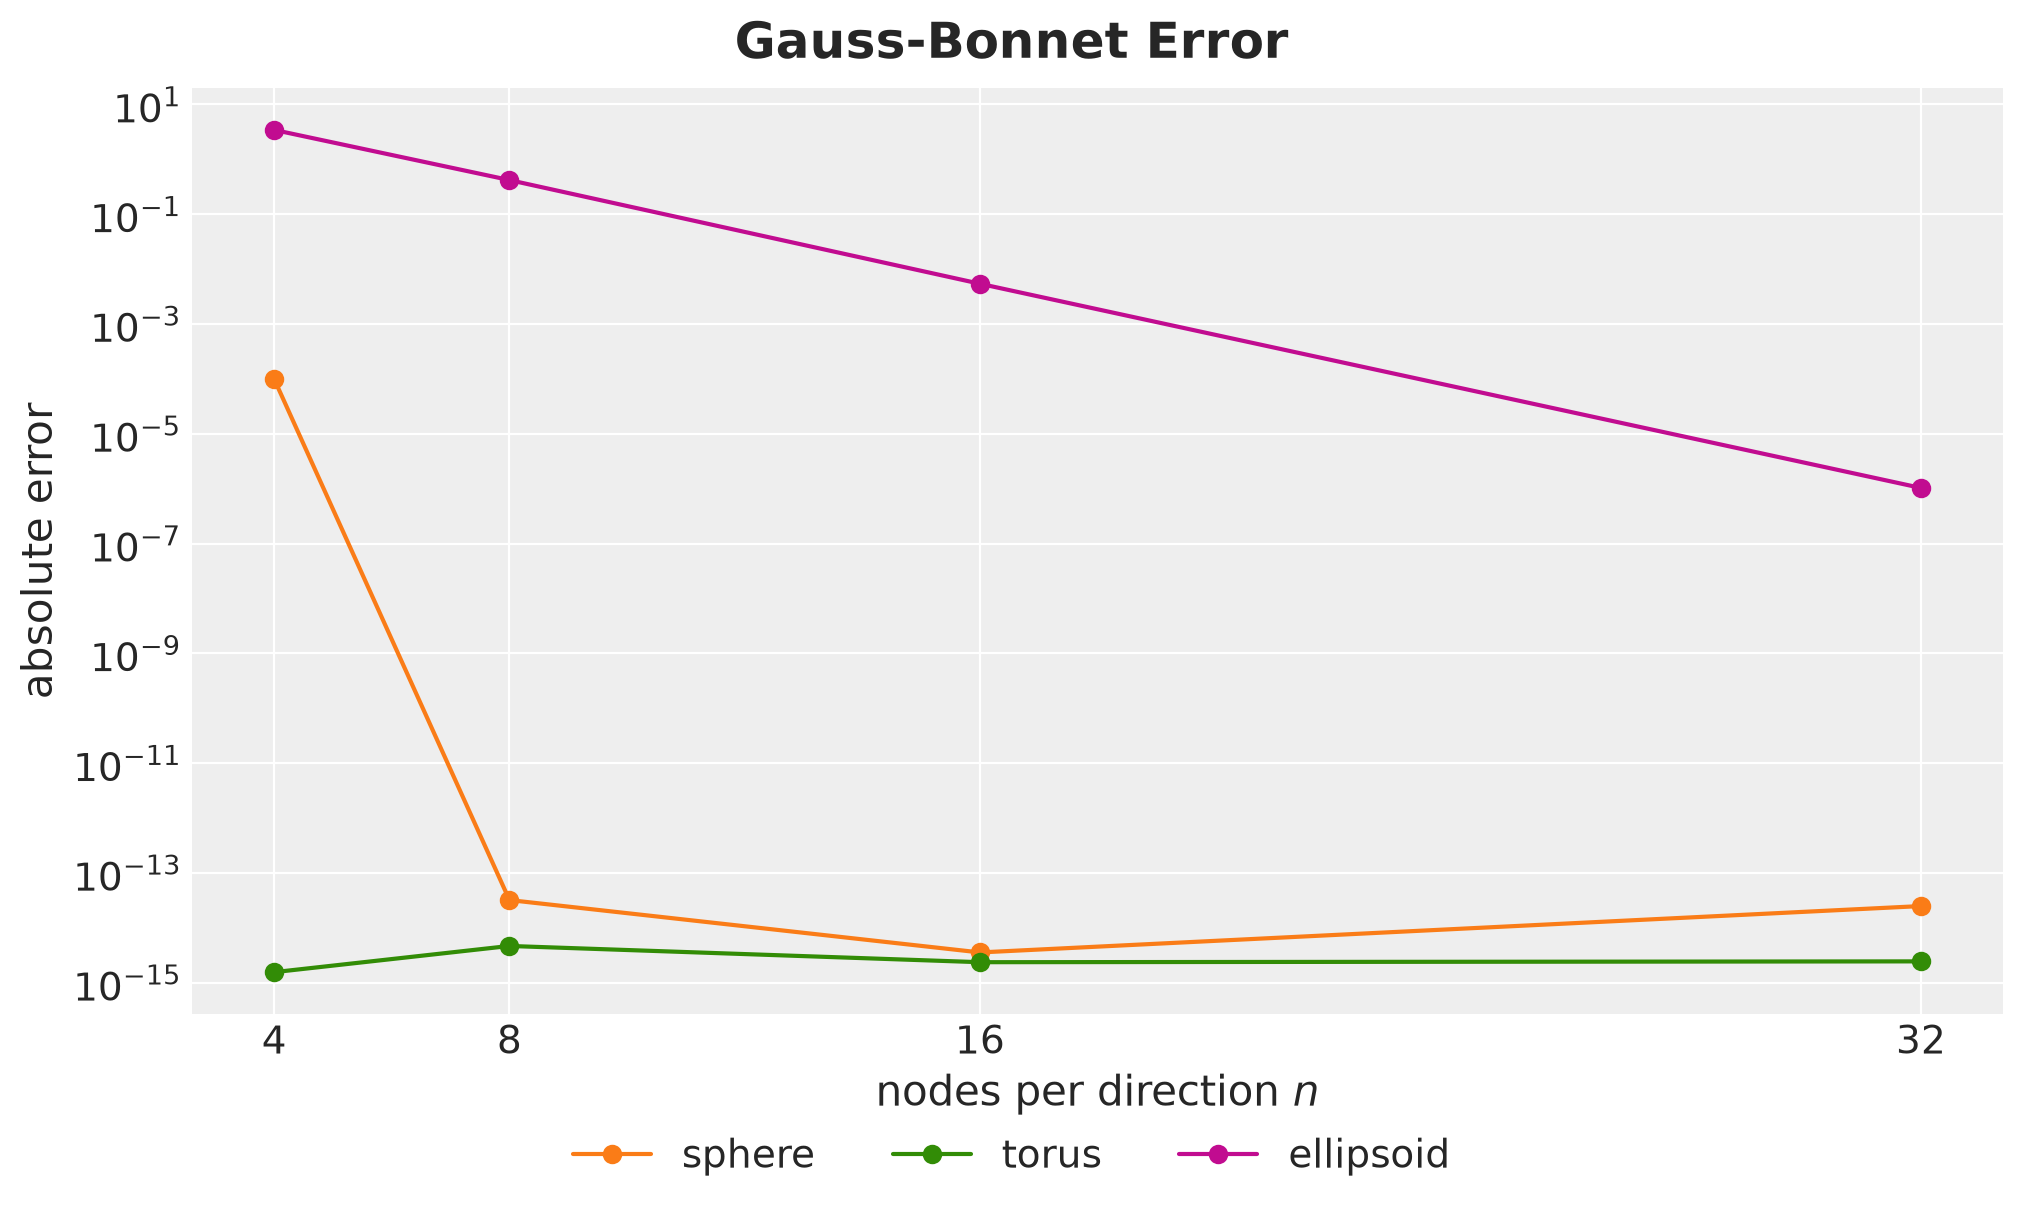

In [15]:
fig, ax = plt.subplots(layout="constrained")

for name, color in SURFACE_COLORS.items():
    rows = results.filter(pl.col("surface") == name)
    ax.plot(rows["n_nodes"], rows["abs_error"], marker="o", color=color, label=name)

ax.set(
    yscale="log",
    xticks=N_NODES,
    xlabel="nodes per direction $n$",
    ylabel="absolute error",
)
fig.legend(loc="outside lower center", ncol=3)
fig.suptitle("Gauss-Bonnet Error", fontsize=18, fontweight="bold");

The three surfaces converge at different rates:

- **Sphere.** The error drops to round-off with $n = 8$ nodes per direction.
- **Torus.** The error stays at round-off for every $n$, as the midpoint rule predicts.
- **Ellipsoid.** The error falls by a constant factor per added node, a straight line on the log axis, which is geometric convergence. It needs more nodes than the sphere, which is consistent with its curvature being concentrated near the ends of its longest axis.

The two sides of the theorem agree for all three surfaces! The cell took about $60$ seconds for the $4080$ points, or about $15$ milliseconds per point.

We close with the lessons that carry over to other surfaces.

## Conclusion

### Key Findings

- **Agreement of both sides.** A tensor-product quadrature of $K \sqrt{\det g}$ converges geometrically to $2\pi\chi$ when each one-dimensional rule follows how its parameter direction closes up.
- **Pointwise checks of the curvature.** Closed forms and the extrinsic route check the nested derivatives of the intrinsic route at a few points, before any integral.
- **Little code per surface.** Given a base class that fixes the embedding space, an `immersion` method is enough for geomstats to derive the metric, the Christoffel symbols, and the Riemann tensor.

### Limitations

- Each surface needs one parametrization over a rectangle with periodic or pole closures. A surface of genus $2$ or more needs several charts or another description.
- Closed forms of $K$ exist only for special surfaces. On a general surface we can only compare the two routes with each other.
- The PyTorch backend differentiates point by point, so the cost grows linearly with the number of points, $n^2$ for $n$ nodes per direction. This is why we stop at $n = 32$.

### Recommendations

1. **Use geomstats from `main` with PyTorch.** The Riemann tensor of an `ImmersedSet` needs nested derivatives, which the PyTorch backend computes correctly only since [#2142](https://github.com/geomstats/geomstats/pull/2142).
2. **Check $K$ pointwise before integrating.** A closed form or the extrinsic route finds index and sign errors at a few points, before you pay for an integral.
3. **Match the quadrature to the closure.** Use the midpoint rule in periodic directions and Gauss-Legendre nodes in directions that end at poles, so that no node falls on a pole.

## Next Steps

1. **Boundary term.** On the cap $\theta \leq \theta_0$ of the unit sphere, the curvature term is $2\pi (1 - \cos\theta_0)$ and the boundary term is $2\pi \cos\theta_0$, which add up to $2\pi$, the value of $2\pi\chi$ for a disk. The geodesic curvature of a boundary curve follows from the Christoffel symbols that geomstats already computes.
2. **Discrete Gauss-Bonnet.** On a triangulated surface, the angle defect at a vertex plays the role of $K \, dA$, and the angle defects sum to $2\pi\chi$ exactly (see [Crane](https://www.cs.cmu.edu/~kmcrane/Projects/DDG/)). We could compare the angle defect divided by a vertex area with $K$ from geomstats on the same surfaces.
3. **Faster derivatives.** The loops over points in `jacobian_vec` and `hessian_vec` set the cost. Batching the nested derivatives with `torch.func.jacrev` and `torch.func.vmap` would remove the loops and make finer quadrature grids cheap.

## References

- Crane, K. [Discrete Differential Geometry: An Applied Introduction](https://www.cs.cmu.edu/~kmcrane/Projects/DDG/). Carnegie Mellon University.
- do Carmo, M. P. [Differential Geometry of Curves and Surfaces](https://store.doverpublications.com/products/9780486806990). Second edition, Dover.
- geomstats. [Fix nested autodiff in pytorch backend (wrong riemann_tensor on ImmersedSet)](https://github.com/geomstats/geomstats/pull/2142). Pull request #2142.
- Miolane, N., et al. [Geomstats: A Python Package for Riemannian Geometry in Machine Learning](https://jmlr.org/papers/v21/19-027.html). Journal of Machine Learning Research 21(223), 2020.
- Trefethen, L. N. [Is Gauss Quadrature Better than Clenshaw-Curtis?](https://doi.org/10.1137/060659831). SIAM Review 50(1), 2008.
- Trefethen, L. N., and Weideman, J. A. C. [The Exponentially Convergent Trapezoidal Rule](https://doi.org/10.1137/130932132). SIAM Review 56(3), 2014.
- Weisstein, E. W. [Ellipsoid](https://mathworld.wolfram.com/Ellipsoid.html). MathWorld.
- Wikipedia. [Gauss-Bonnet theorem](https://en.wikipedia.org/wiki/Gauss%E2%80%93Bonnet_theorem), [Theorema Egregium](https://en.wikipedia.org/wiki/Theorema_Egregium), [Euler characteristic](https://en.wikipedia.org/wiki/Euler_characteristic), [Euler-Maclaurin formula](https://en.wikipedia.org/wiki/Euler%E2%80%93Maclaurin_formula).